In [21]:
import sys
import os

# Проверяем, запущен ли ноутбук в среде Google Colab
if "google.colab" in sys.modules:
    !pip install uv -q
    !wget https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_9/pyproject.toml -q
    !uv pip install -r pyproject.toml --system -q
    os.kill(os.getpid(), 9)  # force runtime restart

# Сравнение стратегий на синтетике

На коротком реальном ряде стратегии прогнозирования оказываются почти равны. Чтобы увидеть, **чем**
они отличаются, нужен эксперимент, где известна «правда» и можно управлять шумом.

Идея: синусоида с периодом 30, в train — 5 периодов с **фазовым** шумом `sin(2πt/30 + ε)`
(значения всегда на синусоиде, но «скачут» по фазе), тест — следующие 3 периода **без шума**.

Сравниваем три стратегии на одном регрессоре (CatBoost), окно = горизонт = период (30):
- **Recursive** — одна модель на шаг вперёд, 30 шагов прогнозируются рекурсивно;
- **RecMIMO** — MIMO-модель на 10 шагов, горизонт 30 собирается из трёх блоков рекурсивно;
- **MIMO** — одна модель сразу на все 30 шагов.

Каждая стратегия обучается один раз на train. Затем прогнозируем 3 периода теста подряд:
прогноз на период дописывается в историю и по нему строится прогноз на следующий период.
На каждом графике — все три «фолда» прогноза, в легенде — MAE каждого.

Дальше — три уточняющих эксперимента: устойчивость к сиду шума, длина окна и DIRMO,
которая плавно переводит прямую стратегию в MIMO.

In [22]:
import common  # первым: глушит предупреждения библиотек при импорте

common.quiet()

import time  # noqa: E402

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from catboost import CatBoostRegressor  # noqa: E402
from sktime.forecasting.base import ForecastingHorizon  # noqa: E402
from sktime.forecasting.compose import make_reduction  # noqa: E402

from common import mae  # noqa: E402


SEED = 0
N_PERIODS_TRAIN, N_PERIODS_TEST, PERIOD = 5, 3, 30
TRAIN_SIZE, TEST_SIZE = N_PERIODS_TRAIN * PERIOD, N_PERIODS_TEST * PERIOD
HORIZON = HISTORY = PERIOD
STDS = [0.1, 0.7, 1]
SEEDS = range(5)


def make_series(std, seed=SEED):
    """Train: синусоида с фазовым шумом. Test: следующие N_PERIODS_TEST периодов без шума."""
    np.random.seed(seed)
    t = np.arange(TRAIN_SIZE + TEST_SIZE) / TRAIN_SIZE
    noise = np.random.normal(0, std, len(t))
    noise[-TEST_SIZE:] = 0
    y = pd.Series(np.sin(2 * np.pi * t * N_PERIODS_TRAIN + noise))
    return y.iloc[:TRAIN_SIZE], y.iloc[TRAIN_SIZE:]


def plot_series(std):
    train, test = make_series(std)
    plt.figure(figsize=[10, 4])
    plt.plot(train, c="b", label="train")
    plt.plot(test, c="r", label="test")
    plt.plot(test.iloc[:HORIZON], c="g", label="forecast period")
    plt.legend()
    plt.title(f"std = {std}")
    plt.show()

### Стратегии

Все три — `make_reduction` из sktime; отличаются стратегией и длиной горизонта модели.
Если модель прогнозирует меньше, чем `HORIZON` (RecMIMO — по 10 шагов), недостающее
добираем рекурсией: дописываем прогноз в историю через `update(..., update_params=False)`
(без переобучения) и прогнозируем следующий блок.

In [23]:
def make_catboost(**kwargs):
    return CatBoostRegressor(
        iterations=300, depth=4, random_seed=0, verbose=False, thread_count=4, allow_writing_files=False, **kwargs
    )


STRATEGIES = {
    "Recursive": ("recursive", HORIZON),
    "RecMIMO": ("multioutput", HORIZON // 3),
    "MIMO": ("multioutput", HORIZON),
}

STRATEGY_COLORS = {"Recursive": "tab:blue", "RecMIMO": "tab:orange", "MIMO": "tab:green"}
FOLD_COLORS = ["g", "darkgreen", "k"]


def fit_strategy(strategy, model_horizon, train, window=HISTORY):
    estimator = make_catboost(loss_function="MultiRMSE") if strategy == "multioutput" else make_catboost()
    forecaster = make_reduction(estimator, strategy=strategy, window_length=window)
    return forecaster.fit(train, fh=ForecastingHorizon(np.arange(1, model_horizon + 1)))


def forecast(forecaster, n_steps):
    """n_steps точек блоками по горизонту модели; каждый блок дописывается в историю."""
    blocks = []
    while sum(map(len, blocks)) < n_steps:
        pred = forecaster.predict()
        forecaster.update(pred, update_params=False)
        blocks.append(pred)
    return pd.concat(blocks).iloc[:n_steps]


def run_case(strategy, model_horizon, train, test, window=HISTORY):
    """Обучаем один раз, затем прогнозируем N_PERIODS_TEST фолдов подряд."""
    forecaster = fit_strategy(strategy, model_horizon, train, window)
    preds = [forecast(forecaster, HORIZON) for _ in range(N_PERIODS_TEST)]
    metrics = [round(mae(test.loc[pred.index], pred), 3) for pred in preds]
    return preds, metrics


def draw_forecast(ax, train, test, preds, metrics, title, legend_fontsize=10):
    """Train, полупрозрачный test и прогнозы всех фолдов; в легенде — MAE каждого."""
    ax.plot(train, c="b", label="train")
    ax.plot(test, c="r", label="test", alpha=0.5)
    for fold, (pred, metric) in enumerate(zip(preds, metrics), start=1):
        label = "forecast period" + ("" if fold == 1 else f" {fold}")
        ax.plot(pred, c=FOLD_COLORS[fold - 1], label=f"{label}, MAE:{metric}")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=legend_fontsize)


def run_std(std):
    """Три графика — по одному на стратегию; возвращает данные для сетки и выводов."""
    plot_series(std)
    train, test = make_series(std)
    results = {}
    for name, (strategy, model_horizon) in STRATEGIES.items():
        preds, metrics = run_case(strategy, model_horizon, train, test)
        results[name] = (preds, metrics)
        _, ax = plt.subplots(figsize=[15, 4])
        draw_forecast(ax, train, test, preds, metrics, f"{name}, std = {std}")
        plt.show()
    return train, test, results

## 1. Эксперимент: три уровня шума

## 1.1. Слабый шум: std = 0.1

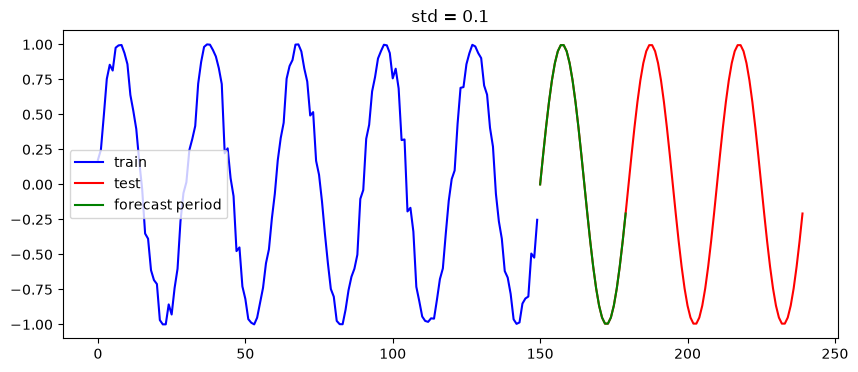

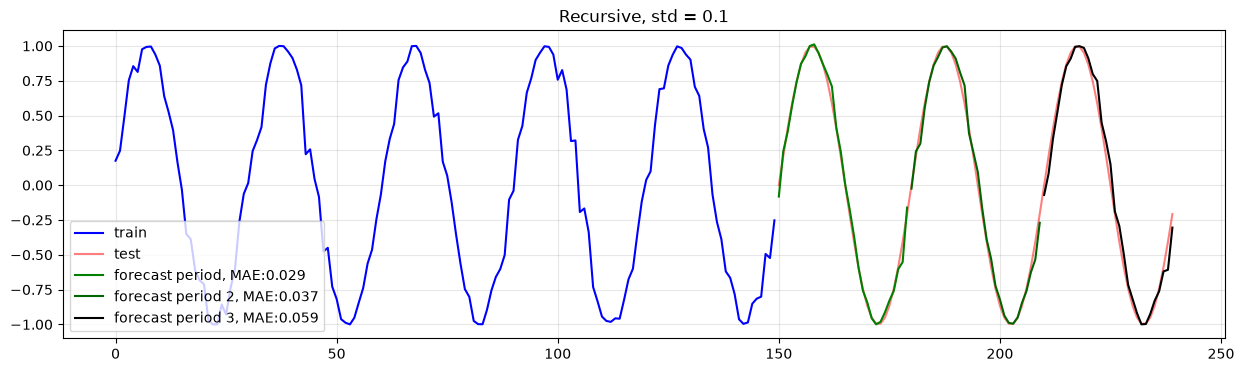

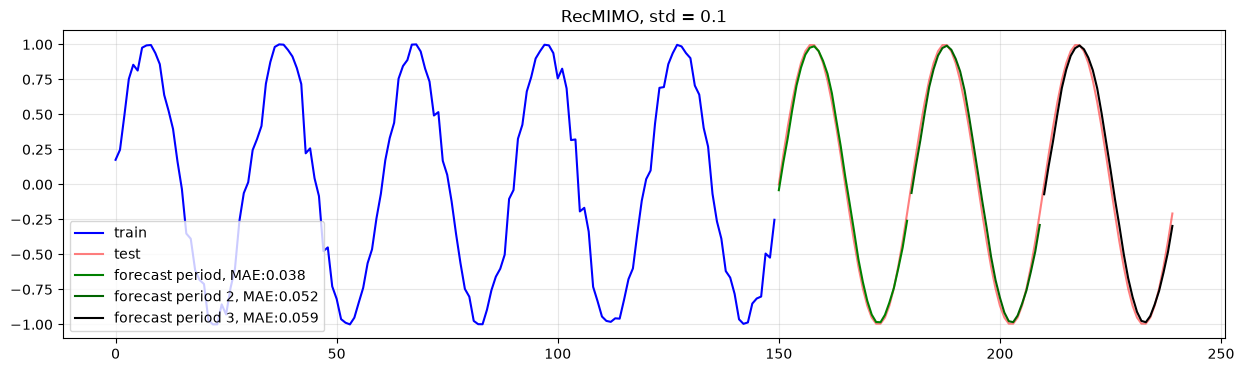

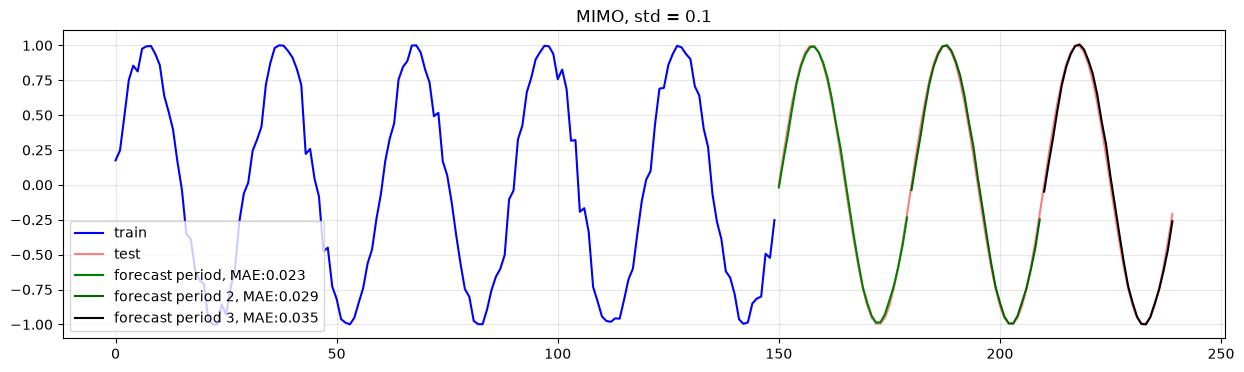

In [4]:
RESULTS = {}
RESULTS[0.1] = run_std(0.1)

## 1.2. Средний шум: std = 0.7

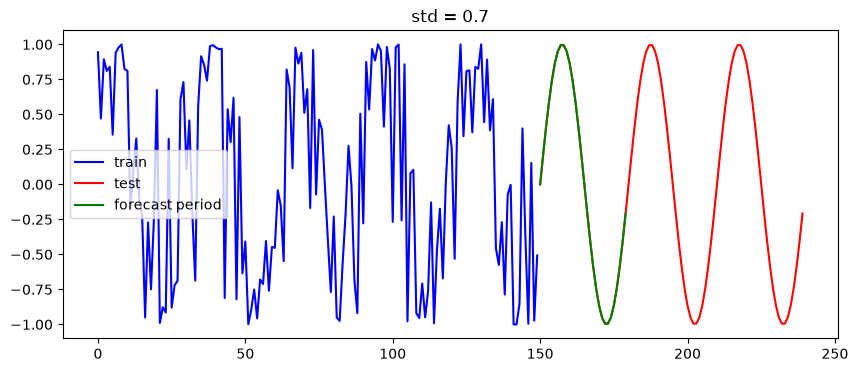

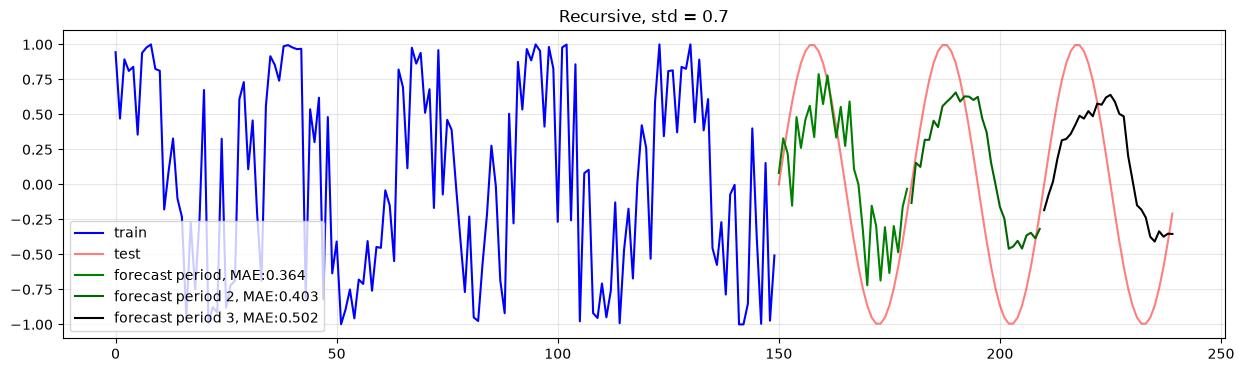

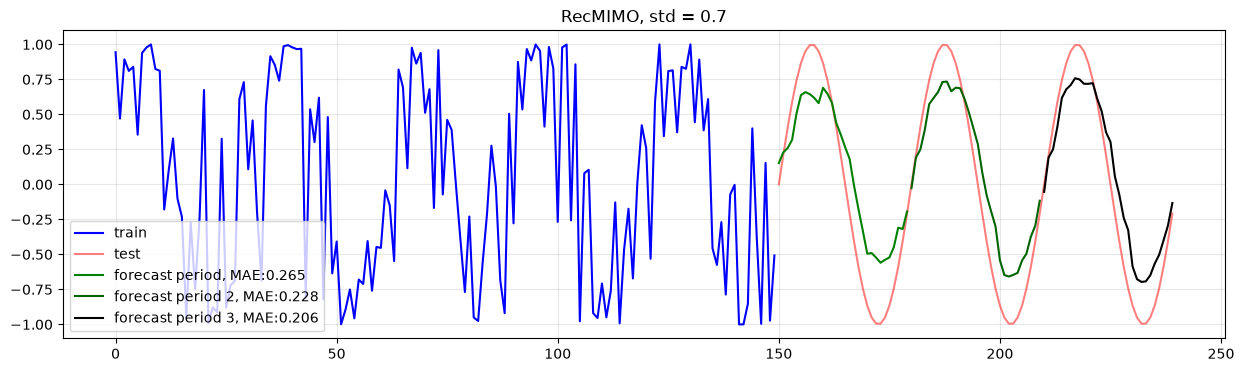

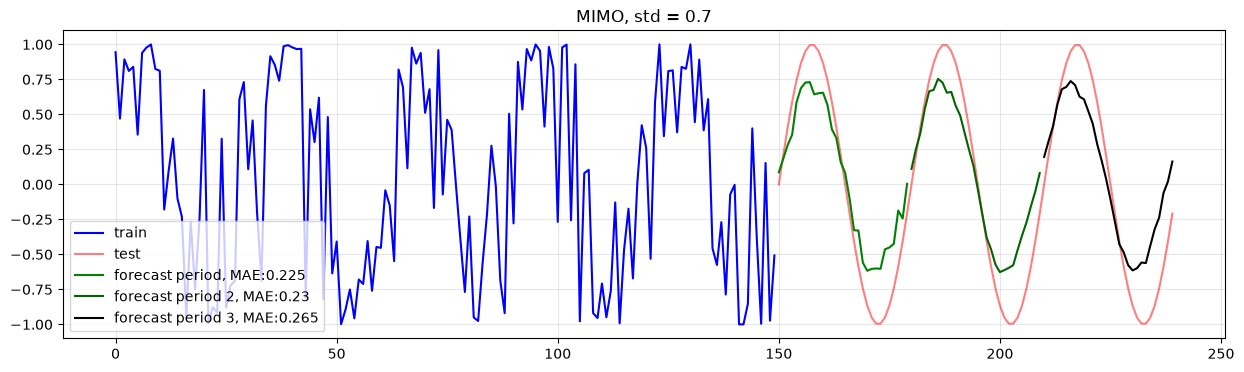

In [5]:
RESULTS[0.7] = run_std(0.7)

## 1.3. Сильный шум: std = 1

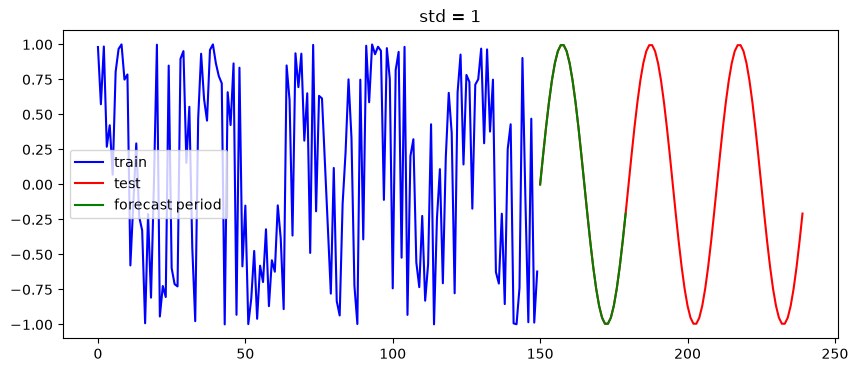

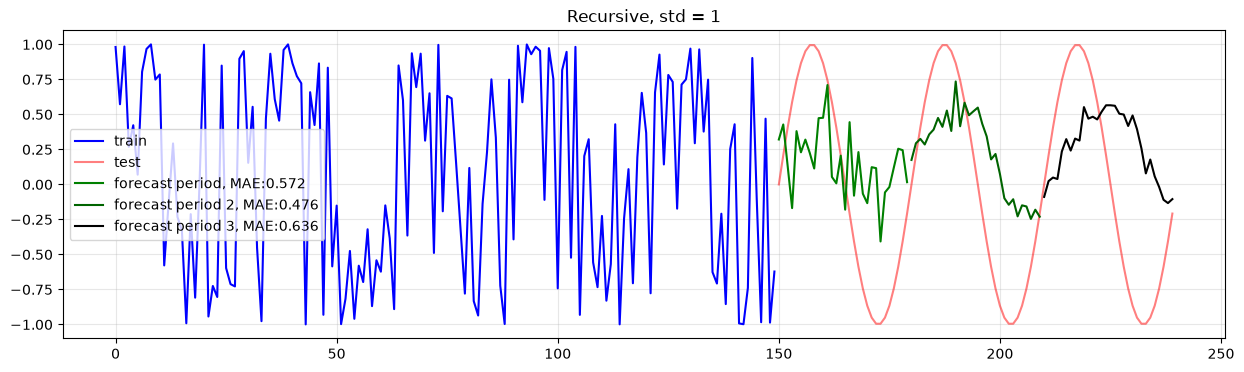

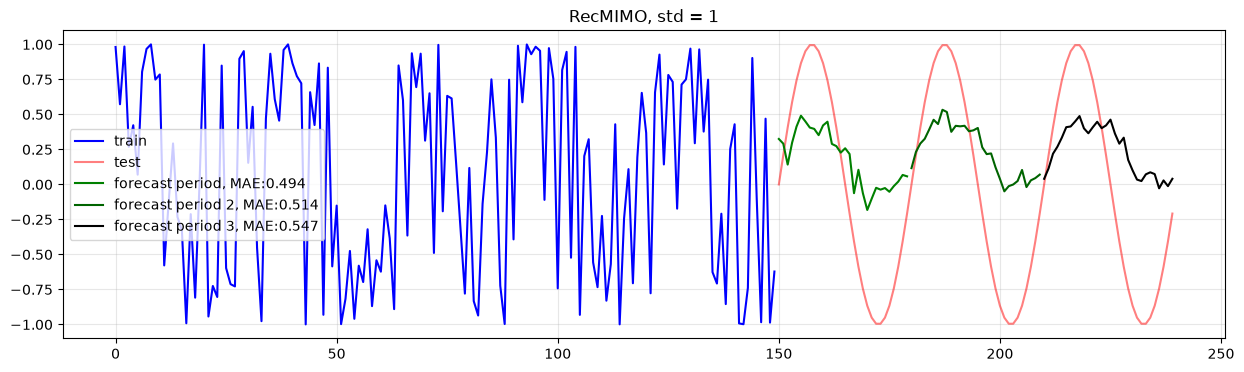

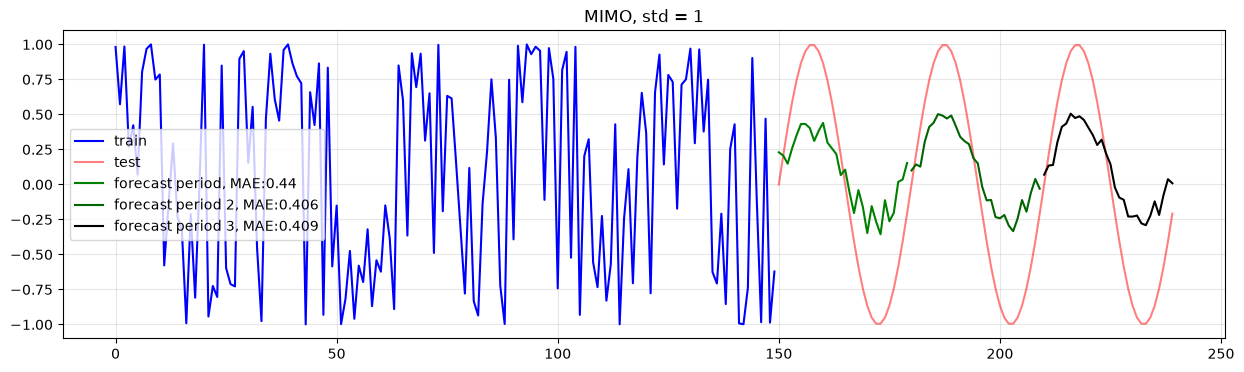

In [6]:
RESULTS[1] = run_std(1)

Средний по трём фолдам MAE:

In [7]:
pd.DataFrame(
    {f"std = {std}": {name: np.mean(metrics) for name, (_, metrics) in results.items()}
     for std, (_, _, results) in RESULTS.items()}
).round(3)

,std = 0.1,std = 0.7,std = 1
Recursive,0.042,0.423,0.561
RecMIMO,0.050,0.233,0.518
MIMO,0.029,0.240,0.418


### Выводы

- **При слабом шуме все три стратегии почти неразличимы** (MAE ≈ 0.03–0.05 на одном сиде): сигнал
  виден через шум, и любая стратегия восстанавливает форму синусоиды.
- **С ростом шума MIMO и RecMIMO отрываются от рекурсии.** При std = 1 на пяти сидах MAE
  рекурсии ≈ 0.50, у RecMIMO и MIMO — ≈ 0.43 и 0.42. MIMO-модель видит все 30 шагов сразу:
  в каждом листе дерева лежит средний вектор будущего по многим окнам, поэтому фазовый шум
  отдельных точек усредняется и прогноз получается «формой», а не набором независимых точек.
- **При окне W = 30 = периоду рекурсия держится**, хотя и хуже остальных: для шага `t+1` в окне
  есть `y(t-29)` — значение ровно период назад, и модель учит что-то близкое к «повтори
  прошлый цикл». Страдает рекурсия сильнее всего на коротком окне (раздел 3).
- **Число фолдов не гарантирует роста ошибки.** На одном сиде у рекурсии третий фолд заметно
  хуже первого (0.029 → 0.059 при std = 0.1), а у RecMIMO при std = 0.7 — наоборот, лучше
  (0.265 → 0.206): прогноз третьего периода опирается на два периода собственных прогнозов,
  но и сам обучался на той же маленькой выборке, поэтому разброс между фолдами — шум, а не
  закономерность. Устойчивая картина видна только на среднем по сидам (раздел 2).
- **Про цену**: рекурсия — одна модель, MIMO — тоже одна, RecMIMO — три (по одной на блок
  горизонта из 10 шагов). На этих данных все три обучаются за десятые доли секунды,
  разница станет заметной в разделе 4.

## 1.4. Все девять картинок рядом

Строки — уровни шума, столбцы — стратегии. В каждом графике те же три фолда и те же MAE,
что и выше.

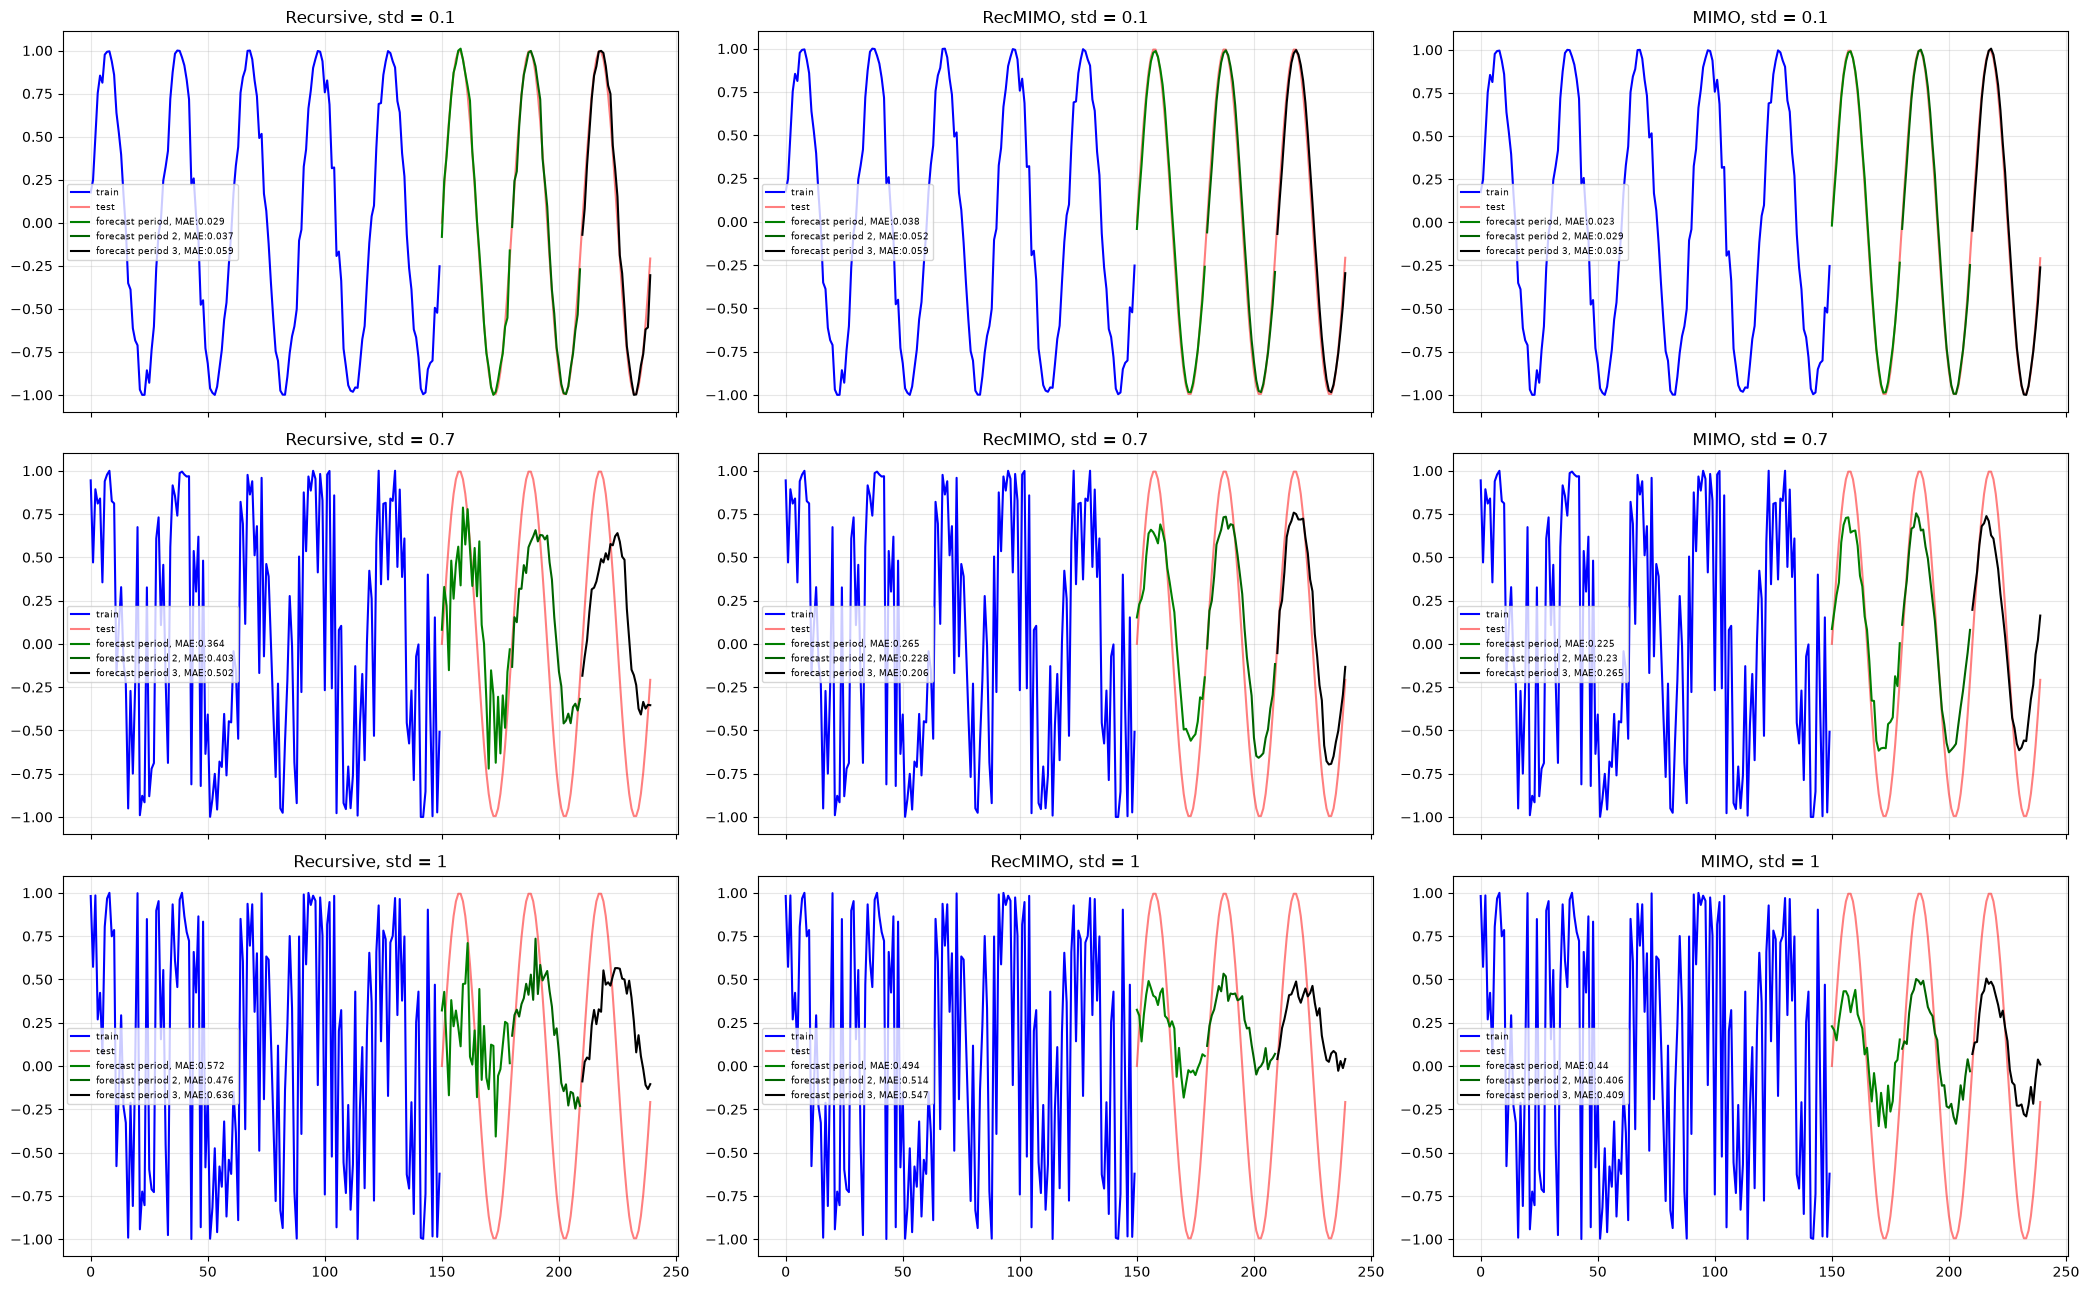

In [8]:
fig, axes = plt.subplots(len(RESULTS), len(STRATEGIES), figsize=(21, 13), sharex=True)
for row, (std, (train, test, results)) in enumerate(RESULTS.items()):
    for col, (name, (preds, metrics)) in enumerate(results.items()):
        draw_forecast(axes[row, col], train, test, preds, metrics, f"{name}, std = {std}", legend_fontsize=6.5)
fig.tight_layout()
plt.show()

## 2. Устойчивость к сиду: среднее по пяти сидам

Один сид может случайно «подвезти» или «подвести» стратегию. Повторяем эксперимент на пяти
сидах шума и усредняем MAE по сидам и по трём фолдам — уже по шагам горизонта.

In [9]:
def mean_errors(std, seeds=SEEDS, window=HISTORY):
    """MAE по шагам горизонта: среднее по сидам и по фолдам; плюс время на один фолд с обучением."""
    by_horizon = {name: [] for name in STRATEGIES}
    seconds = {name: [] for name in STRATEGIES}
    for seed in seeds:
        train, test = make_series(std, seed)
        for name, (strategy, model_horizon) in STRATEGIES.items():
            start = time.perf_counter()
            preds, _ = run_case(strategy, model_horizon, train, test, window)
            seconds[name].append((time.perf_counter() - start) / N_PERIODS_TEST)
            errors = [np.abs(test.loc[pred.index].to_numpy() - pred.to_numpy()) for pred in preds]
            by_horizon[name].append(np.concatenate(errors).reshape(N_PERIODS_TEST, HORIZON).mean(axis=0))
    return {name: np.mean(e, axis=0) for name, e in by_horizon.items()}, {name: np.mean(t) for name, t in seconds.items()}


SEED_ERRORS = {std: mean_errors(std) for std in STDS}

segments = {"h 1–5": slice(0, 5), "h 6–15": slice(5, 15), "h 16–30": slice(15, 30)}
pd.DataFrame(
    {
        (f"std = {std}", name): {"MAE": e.mean(), **{seg: e[s].mean() for seg, s in segments.items()}, "время, с": SEED_ERRORS[std][1][name]}
        for std, (errors, _) in SEED_ERRORS.items()
        for name, e in errors.items()
    }
).T.round(3)

MAE  h 1–5  h 6–15  h 16–30  время, с
std = 0.1 Recursive  0.041  0.050   0.034    0.042     0.054
          RecMIMO    0.036  0.040   0.028    0.040     0.218
          MIMO       0.037  0.046   0.036    0.036     0.381
std = 0.7 Recursive  0.324  0.265   0.294    0.363     0.043
          RecMIMO    0.253  0.146   0.299    0.258     0.109
          MIMO       0.250  0.121   0.305    0.257     0.242
std = 1   Recursive  0.503  0.275   0.557    0.543     0.034
          RecMIMO    0.431  0.203   0.474    0.478     0.125
          MIMO       0.419  0.219   0.502    0.430     0.298

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

... (20 outputs left out)

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

MAE  h 1–5  h 6–15  h 16–30  время, с
std = 0.1 Recursive  0.041  0.050   0.034    0.042     0.028
          RecMIMO    0.036  0.040   0.028    0.040     0.111
          MIMO       0.037  0.046   0.036    0.036     0.231
std = 0.7 Recursive  0.324  0.265   0.294    0.363     0.028
          RecMIMO    0.253  0.146   0.299    0.258     0.102
          MIMO       0.250  0.121   0.305    0.257     0.232
std = 1   Recursive  0.503  0.275   0.557    0.543     0.030
          RecMIMO    0.431  0.203   0.474    0.478     0.101
          MIMO       0.419  0.219   0.502    0.430     0.235

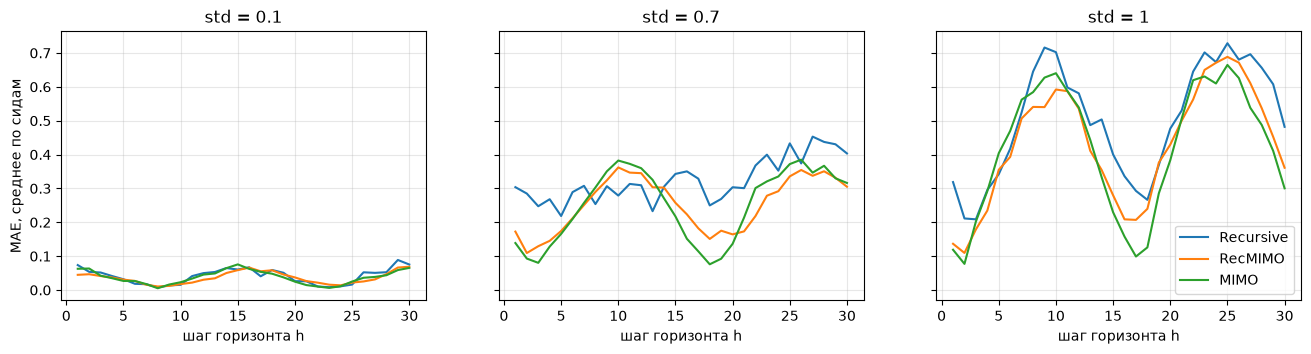

In [10]:
fig, axes = plt.subplots(1, len(STDS), figsize=(16, 3.5), sharey=True)
for ax, (std, (errors, _)) in zip(axes, SEED_ERRORS.items()):
    for name, e in errors.items():
        ax.plot(np.arange(1, HORIZON + 1), e, color=STRATEGY_COLORS[name], label=name)
    ax.set_title(f"std = {std}")
    ax.set_xlabel("шаг горизонта h")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("MAE, среднее по сидам")
axes[-1].legend();

- При std = 0.1 кривые сливаются: разница между стратегиями меньше разброса по сидам.
- При сильном шуме у всех стратегий первые 5 шагов горизонта предсказываются заметно лучше
  дальних (у MIMO при std = 1: 0.22 против 0.50 на шагах 6–15), но **разница между стратегиями
  сосредоточена именно в первых шагах** — там MIMO и RecMIMO лучше рекурсии примерно в полтора
  раза. На шагах 16–30 все три сближаются: информации об истинном ходе синусоиды к этому
  моменту почти не остаётся.
- По времени рекурсия в 8 раз дешевле MIMO на один фолд (0.03 с против 0.23 с): MIMO-модель
  учит вектор из 30 выходов, рекурсия — одно число.

## 3. Окно короче периода: рекурсия ведёт себя хуже

Уменьшим окно до W = 10 (треть периода). Теперь для рекурсии в окне нет «прошлого цикла»:
сама модель должна «вести» синусоиду по своим же прогнозам.

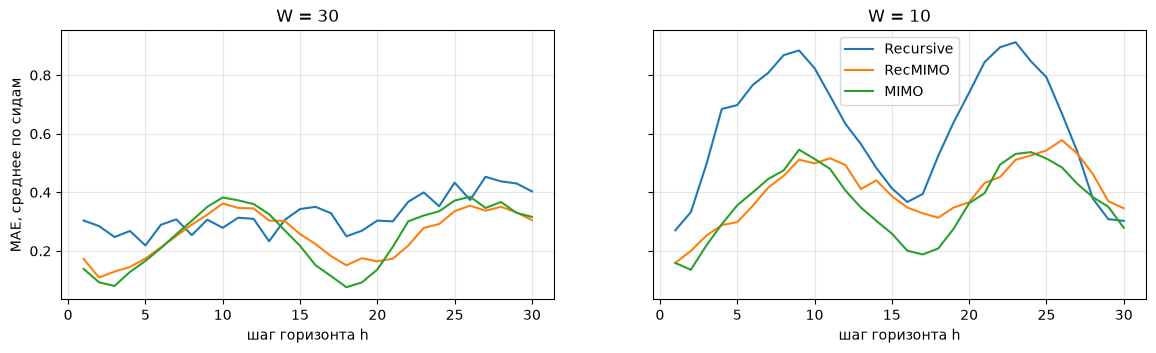

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

... (6 outputs left out)

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

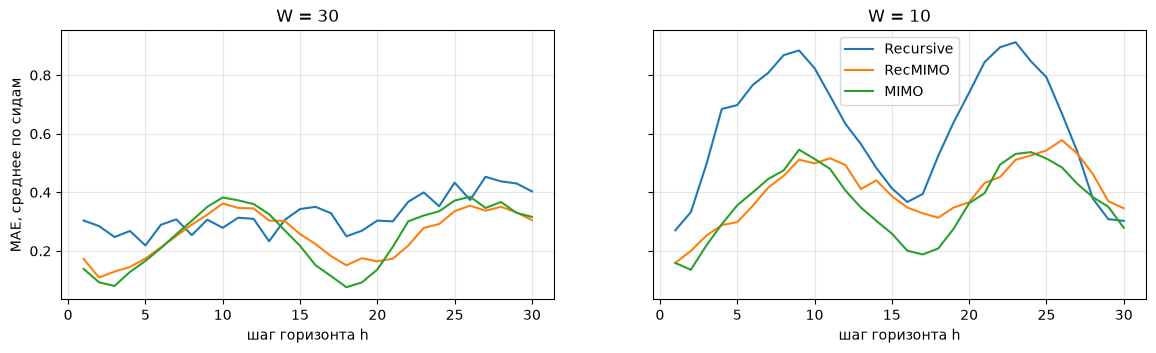

In [11]:
WINDOW_ERRORS = {window: mean_errors(STDS[1], window=window)[0] for window in (HISTORY, 10)}

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5), sharey=True)
for ax, (window, errors) in zip(axes, WINDOW_ERRORS.items()):
    for name, e in errors.items():
        ax.plot(np.arange(1, HORIZON + 1), e, color=STRATEGY_COLORS[name], label=name)
    ax.set_title(f"W = {window}")
    ax.set_xlabel("шаг горизонта h")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("MAE, среднее по сидам")
axes[-1].legend();

In [12]:
pd.DataFrame({f"W = {window}": {name: e.mean() for name, e in errors.items()} for window, errors in WINDOW_ERRORS.items()}).round(3)

,W = 30,W = 10
Recursive,0.324,0.620
RecMIMO,0.253,0.405
MIMO,0.250,0.366


При коротком окне рекурсия становится худшей стратегией: ошибки первых шагов попадают в окно
и переносятся на следующие, а расти они могут волнами — вокруг пиков и впадин синусоиды.
MIMO и RecMIMO от длины окна страдают гораздо меньше: они не подставляют свои прогнозы на вход.

Вывод: «рекурсия накапливает ошибку» верно не всегда — это зависит от того, насколько окно
описывает динамику ряда. Длина окна — такой же важный гиперпараметр, как выбор стратегии.

## 4. DIRMO: от прямой к MIMO

Размер блока `s` плавно переводит DIRMO от прямой стратегии (`s = 1`, по модели на шаг)
к MIMO (`s = H`, одна модель на весь горизонт). Каждая модель — `make_reduction` по своему
участку горизонта, без рекурсии: все блоки прогнозируются по одной и той же истории.

In [13]:
def dirmo_forecast(current, s, window=HISTORY):
    """Все H шагов H/s MIMO-моделями, каждая на свой блок горизонта."""
    blocks = []
    for start in range(0, HORIZON, s):
        fh = ForecastingHorizon(np.arange(start + 1, min(start + s, HORIZON) + 1))
        forecaster = make_reduction(make_catboost(loss_function="MultiRMSE"), strategy="multioutput", window_length=window)
        blocks.append(forecaster.fit(current, fh=fh).predict())
    return pd.concat(blocks)


train, test = make_series(STDS[1], SEED)
mimo = fit_strategy("multioutput", HORIZON, train)
print(f"dirmo(s = {HORIZON}) совпадает с MIMO: {np.allclose(dirmo_forecast(train, HORIZON), mimo.predict())}")

dirmo(s = 30) совпадает с MIMO: True


dirmo(s = 30) совпадает с MIMO: True


In [14]:
S_VALUES = (1, 3, 5, 10, 15, 30)
dirmo_rows = {}
for s in S_VALUES:
    per_seed, seconds = [], []
    for seed in SEEDS:
        train, test = make_series(STDS[1], seed)
        current, errors = train, []
        start = time.perf_counter()
        for step in range(N_PERIODS_TEST):
            pred = dirmo_forecast(current, s)
            errors.append(np.abs(test.iloc[step * HORIZON : (step + 1) * HORIZON].to_numpy() - pred.to_numpy()))
            current = pd.concat([current, pd.Series(pred.to_numpy(), index=np.arange(len(current), len(current) + HORIZON))])
        per_seed.append(np.concatenate(errors).reshape(N_PERIODS_TEST, HORIZON).mean(axis=0))
        seconds.append((time.perf_counter() - start) / N_PERIODS_TEST)
    dirmo_rows[f"s = {s}"] = {"моделей": -(-HORIZON // s), "MAE": np.mean(per_seed).round(3), "время, с": round(np.mean(seconds), 3)}

dirmo_table = pd.DataFrame(dirmo_rows).T
dirmo_table

,моделей,MAE,"время, с"
s = 1,30.0,0.239,2.158
s = 3,10.0,0.239,1.327
s = 5,6.0,0.241,1.153
s = 10,3.0,0.249,0.976
s = 15,2.0,0.248,0.973
s = 30,1.0,0.245,1.043


/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``Tru

... (361 outputs left out)

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(


/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(


/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_9/.venv/lib/python3.11/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(


,моделей,MAE,"время, с"
s = 1,30.0,0.239,2.303
s = 3,10.0,0.239,1.425
s = 5,6.0,0.241,1.232
s = 10,3.0,0.249,0.987
s = 15,2.0,0.248,1.036
s = 30,1.0,0.245,0.936


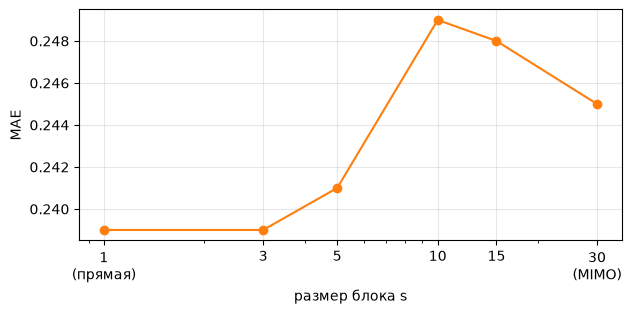

In [15]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot([int(s) for s in S_VALUES], dirmo_table["MAE"], marker="o", color="tab:orange")
ax.set_xlabel("размер блока s")
ax.set_ylabel("MAE")
ax.set_xscale("log")
ax.set_xticks(list(S_VALUES), ["1\n(прямая)", *S_VALUES[1:-1], "30\n(MIMO)"])
ax.grid(alpha=0.3);

На этих данных MAE практически не зависит от размера блока: 0.239 при `s = 1` и 0.245 при
`s = 30`, все промежуточные значения — в том же коридоре. Фазовый шум, в отличие от аддитивного,
не усредняется соседними шагами внутри блока, поэтому дробление горизонта ничего не выигрывает.

А вот цена различается в разы: 30 моделей при `s = 1` обучаются 2.2 с на фолд, одна при `s = 30` —
0.9 с. Практический вывод: **дробить горизонт на мелкие блоки незачем** — либо `s = 1`
(прямая, когда нужны свежие признаки на каждый шаг), либо MIMO.

Для сравнения картинка для **аддитивного** шума -- тут эффект обратный

In [16]:
def make_series_additive(std, seed=SEED):
    """Train: синусоида с фазовым шумом. Test: следующие N_PERIODS_TEST периодов без шума."""
    np.random.seed(seed)
    t = np.arange(TRAIN_SIZE + TEST_SIZE) / TRAIN_SIZE
    noise = np.random.normal(0, std, len(t))
    noise[-TEST_SIZE:] = 0
    y = pd.Series(np.sin(2 * np.pi * t * N_PERIODS_TRAIN) + noise)
    return y.iloc[:TRAIN_SIZE], y.iloc[TRAIN_SIZE:]
    
S_VALUES = (1, 3, 5, 10, 15, 30)
dirmo_rows = {}
for s in S_VALUES:
    per_seed, seconds = [], []
    for seed in SEEDS:
        train, test = make_series_additive(STDS[1], seed)
        current, errors = train, []
        start = time.perf_counter()
        for step in range(N_PERIODS_TEST):
            pred = dirmo_forecast(current, s)
            errors.append(np.abs(test.iloc[step * HORIZON : (step + 1) * HORIZON].to_numpy() - pred.to_numpy()))
            current = pd.concat([current, pd.Series(pred.to_numpy(), index=np.arange(len(current), len(current) + HORIZON))])
        per_seed.append(np.concatenate(errors).reshape(N_PERIODS_TEST, HORIZON).mean(axis=0))
        seconds.append((time.perf_counter() - start) / N_PERIODS_TEST)
    dirmo_rows[f"s = {s}"] = {"моделей": -(-HORIZON // s), "MAE": np.mean(per_seed).round(3), "время, с": round(np.mean(seconds), 3)}

dirmo_table = pd.DataFrame(dirmo_rows).T
dirmo_table

,моделей,MAE,"время, с"
s = 1,30.0,0.224,2.142
s = 3,10.0,0.222,1.357
s = 5,6.0,0.224,1.221
s = 10,3.0,0.218,0.972
s = 15,2.0,0.205,0.956
s = 30,1.0,0.210,0.965


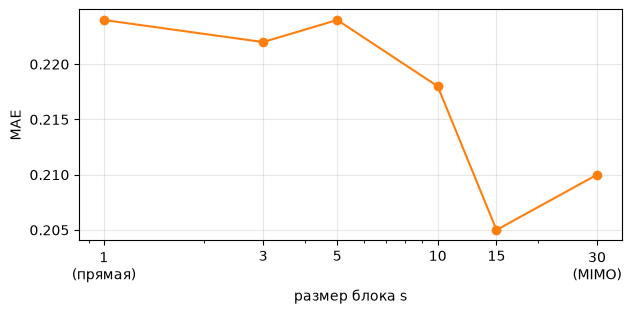

In [19]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot([int(s) for s in S_VALUES], dirmo_table["MAE"], marker="o", color="tab:orange")
ax.set_xlabel("размер блока s")
ax.set_ylabel("MAE")
ax.set_xscale("log")
ax.set_xticks(list(S_VALUES), ["1\n(прямая)", *S_VALUES[1:-1], "30\n(MIMO)"])
ax.grid(alpha=0.3);